# Task 03 – Student Performance Prediction (Regression)

**Problem statement:** predict a student's **Performance Index** from study habits and previous scores,
so teachers can spot students who need help early.

**Task type:** supervised **regression** – target `Performance Index` (10 – 100).

**Dataset:** Student Performance – 10,000 students, 5 features + target.

| Column | Meaning |
|---|---|
| Hours Studied | hours studied per day |
| Previous Scores | score in previous exams (40 – 99) |
| Extracurricular Activities | Yes / No |
| Sleep Hours | average sleep per day |
| Sample Question Papers Practiced | number of practice papers |
| **Performance Index** | **target** – overall performance (10 – 100) |

**Metrics:** R² (main), MAE, MSE, RMSE – models compared with **5-fold cross-validation on the training data**, the test set is used once at the end.

This task is also **deployed** as a Gradio app (`app.py`).

# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also hide warnings inside the parallel workers (n_jobs=-1)
%matplotlib inline
sns.set_theme(style='whitegrid')

# Read data

In [2]:
df = pd.read_csv('dataset/Student_Performance.csv')
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [3]:
df.shape

(10000, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [5]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


# Data Understanding

- 4 numeric features + 1 Yes/No feature; the target is a number → **regression**.
- `Extracurricular Activities` and `Sample Question Papers Practiced` have missing values (see below).

# Data Cleaning

In [6]:
df.isnull().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1572
Sleep Hours                            0
Sample Question Papers Practiced    2856
Performance Index                      0
dtype: int64

- `Extracurricular Activities`: 1,572 missing → filled with the **most frequent** value.
- `Sample Question Papers Practiced`: 2,856 missing (29 %) → filled with the **median** (dropping them would lose almost a third of the data).
- Both are done **inside the Pipeline**, so the fill values come from the training data only.

In [7]:
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

Number of duplicate rows :  132


(9868, 6)

Duplicates are removed **before** the split so the same student can't be in both train and test (data leakage).

# EDA & Statistical Analysis

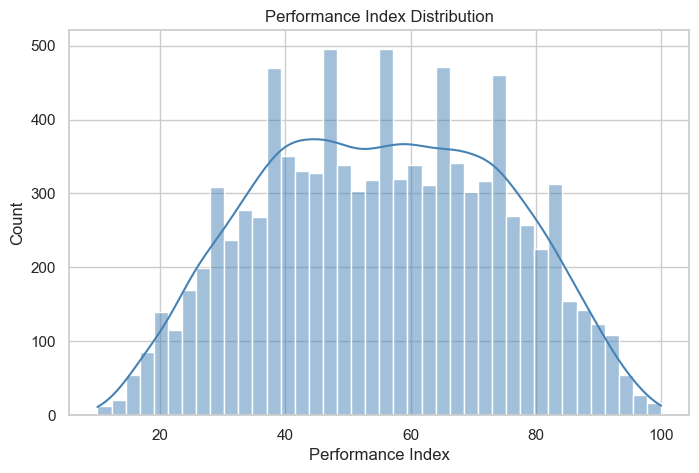

Skewness: -0.0


In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Performance Index'], bins=40, color='steelblue', kde=True)
plt.title('Performance Index Distribution')
plt.show()
print('Skewness:', round(df['Performance Index'].skew(), 2))

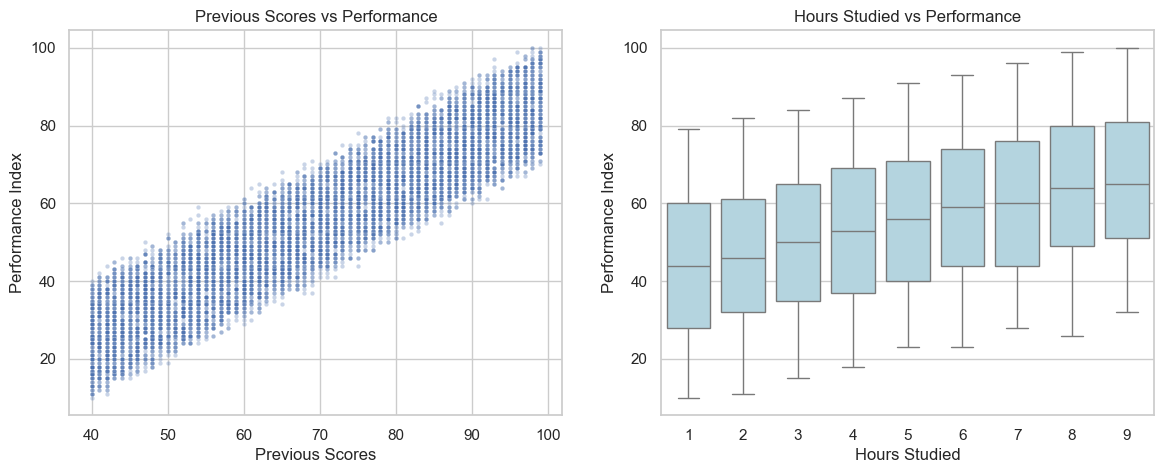

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x='Previous Scores', y='Performance Index', data=df, alpha=0.3, s=10, ax=ax[0])
ax[0].set_title('Previous Scores vs Performance')
sns.boxplot(x='Hours Studied', y='Performance Index', data=df, color='lightblue', ax=ax[1])
ax[1].set_title('Hours Studied vs Performance')
plt.show()

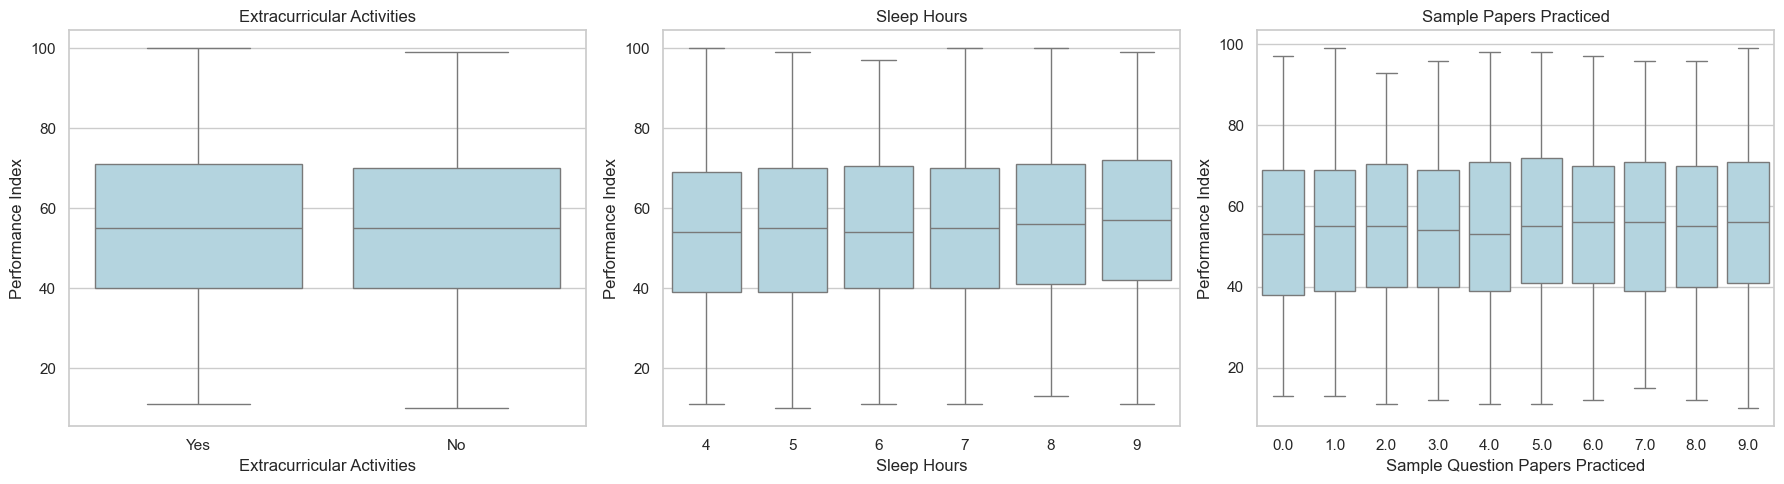

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x='Extracurricular Activities', y='Performance Index', data=df, color='lightblue', ax=ax[0])
ax[0].set_title('Extracurricular Activities')
sns.boxplot(x='Sleep Hours', y='Performance Index', data=df, color='lightblue', ax=ax[1])
ax[1].set_title('Sleep Hours')
sns.boxplot(x='Sample Question Papers Practiced', y='Performance Index', data=df, color='lightblue', ax=ax[2])
ax[2].set_title('Sample Papers Practiced')
plt.tight_layout()
plt.show()

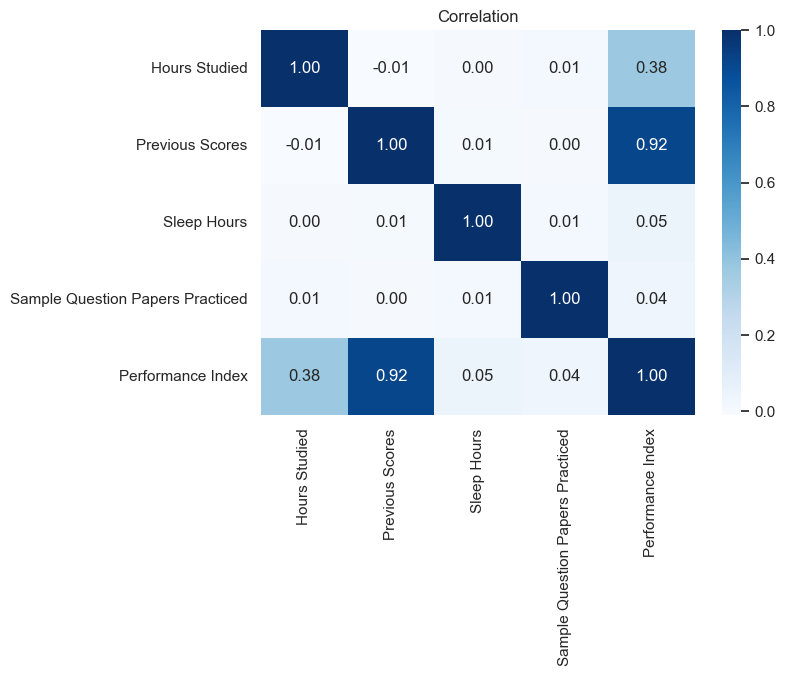

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation')
plt.show()

In [12]:
from scipy.stats import ttest_ind, pearsonr

yes = df[df['Extracurricular Activities'] == 'Yes']['Performance Index']
no = df[df['Extracurricular Activities'] == 'No']['Performance Index']
print(f'Extracurricular: mean Yes = {yes.mean():.2f}  mean No = {no.mean():.2f}  t-test p-value = {ttest_ind(yes, no).pvalue:.4f}')

for col in ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']:
    data = df[[col, 'Performance Index']].dropna()
    r, p = pearsonr(data[col], data['Performance Index'])
    print(f'{col:34s} correlation = {r:.3f}   p-value = {p:.4g}')

Extracurricular: mean Yes = 55.70  mean No = 54.68  t-test p-value = 0.0161
Hours Studied                      correlation = 0.375   p-value = 0
Previous Scores                    correlation = 0.915   p-value = 0
Sleep Hours                        correlation = 0.050   p-value = 7.94e-07
Sample Question Papers Practiced   correlation = 0.036   p-value = 0.002633


**EDA findings**
- **Target:** Performance Index is almost normally distributed (skewness ≈ 0), from 10 to 100 → no transformation needed.
- **Previous Scores** has a very strong straight-line relation with performance (r = 0.92).
- **Hours Studied** is the second factor (r = 0.37): mean performance goes from 44 (1 hour) to 66 (9 hours), almost +2.8 points per hour.
- **Sleep Hours** (r = 0.05) and **Sample Papers** (r = 0.04) have small but **significant** effects (p < 0.01).
- Students with **extracurricular activities** score about 1 point higher (t-test p = 0.016 → significant).
- The features are almost **not correlated with each other** → each one adds its own information.

# Outliers

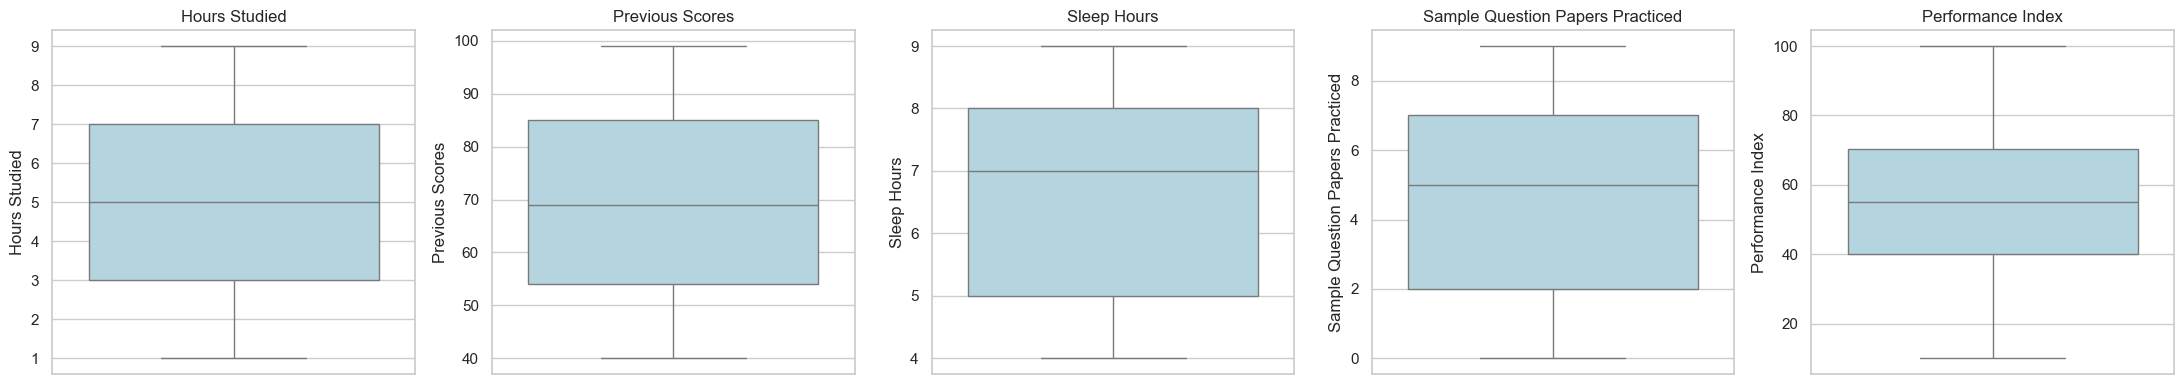

Hours Studied                      outliers = 0
Previous Scores                    outliers = 0
Sleep Hours                        outliers = 0
Sample Question Papers Practiced   outliers = 0
Performance Index                  outliers = 0


In [13]:
num_features = ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']

fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for i, col in enumerate(num_features):
    sns.boxplot(y=df[col], color='lightblue', ax=ax[i])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

for col in num_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    print(f'{col:34s} outliers = {((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()}')

**No outliers** by the IQR rule – all values are inside normal ranges (e.g. sleep 4–9 hours, scores 40–99), so nothing is removed.

# Feature Engineering / Selection

- **Feature engineering is not needed here:** the features are already clean numbers, and the EDA shows **straight-line** relations with the target
  (more study hours or higher previous scores → higher performance). New features would not add information.
- **Feature selection:** every feature has a **significant** relation with the target (all p-values < 0.05). `Previous Scores` (r ≈ 0.92) and `Hours Studied` (r ≈ 0.37) are the strongest;
  `Sleep Hours` and `Sample Papers` are weak alone but still significant, so **all 5 features are kept**.

In [14]:
num_cols = ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']
cat_cols = ['Extracurricular Activities']

# Split data

In [15]:
from sklearn.model_selection import train_test_split

X = df[num_cols + cat_cols]
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (7894, 5)  y_train =  (7894,)
X_test  =  (1974, 5)  y_test  =  (1974,)


# Preprocessing (Pipeline + ColumnTransformer)

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))   # Yes / No -> one 0/1 column
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

- **Imputation:** median / most frequent, learned from the training data only.
- **Scaling:** `StandardScaler` – needed by KNN, SVR and the regularized linear models.
- **Encoding:** `Extracurricular Activities` (Yes / No) becomes one 0/1 column.
- Everything is in one **Pipeline**, which is also what the deployed app loads.

# Models

| Model | Why it is tried |
|---|---|
| Linear Regression | the EDA shows straight-line relations → a strong candidate |
| Ridge / Lasso / ElasticNet | linear + regularization (L2 / L1 / both) |
| KNN Regressor | students with similar habits have similar results |
| Decision Tree | non-linear rules, easy to read, but overfits |
| Random Forest / Extra Trees | many trees averaged → less overfitting |
| SVR | non-linear (RBF kernel) on scaled data |
| Gradient Boosting / AdaBoost | boosting: each tree corrects the previous ones |
| XGBoost / LightGBM | fast, regularized gradient boosting |

**Excluded:** classification models (the target is a number).

In [17]:
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [18]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.01),
    'ElasticNet': ElasticNet(alpha=0.01, l1_ratio=0.5),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'SVR': SVR(kernel='rbf'),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'Extra Trees': ExtraTreesRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'LightGBM': LGBMRegressor(random_state=42, verbose=-1),
}

## Model comparison with 5-fold cross-validation (training data only)

In [19]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error', 'MSE': 'neg_mean_squared_error', 'RMSE': 'neg_root_mean_squared_error'}

results = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    cv = cross_validate(pipe, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    results[name] = {
        'Train R2': cv['train_R2'].mean(),
        'CV R2': cv['test_R2'].mean(),
        'CV MAE': -cv['test_MAE'].mean(),
        'CV MSE': -cv['test_MSE'].mean(),
        'CV RMSE': -cv['test_RMSE'].mean(),
    }
    print(f"{name:18s}  CV R2 = {results[name]['CV R2']:.4f}")

Linear Regression   CV R2 = 0.9883


Ridge               CV R2 = 0.9883
Lasso               CV R2 = 0.9883
ElasticNet          CV R2 = 0.9882
KNN                 CV R2 = 0.9737


Decision Tree       CV R2 = 0.9743


Random Forest       CV R2 = 0.9842


SVR                 CV R2 = 0.9842


Gradient Boosting   CV R2 = 0.9874


AdaBoost            CV R2 = 0.9765


Extra Trees         CV R2 = 0.9813
XGBoost             CV R2 = 0.9854


LightGBM            CV R2 = 0.9872


In [20]:
comparison = pd.DataFrame(results).T.sort_values('CV R2', ascending=False)
comparison.round(4)

,Train R2,CV R2,CV MAE,CV MSE,CV RMSE
Ridge,0.9883,0.9883,1.6471,4.3058,2.0750
Linear Regression,0.9883,0.9883,1.6471,4.3058,2.0750
Lasso,0.9883,0.9883,1.6472,4.3067,2.0752
ElasticNet,0.9883,0.9882,1.6493,4.3165,2.0776
Gradient Boosting,0.9885,0.9874,1.7109,4.6250,2.1506
LightGBM,0.9901,0.9872,1.7195,4.6826,2.1639
XGBoost,0.9936,0.9854,1.8374,5.3521,2.3134
Random Forest,0.9972,0.9842,1.9184,5.7886,2.4057
SVR,0.9848,0.9842,1.8799,5.8028,2.4082
Extra Trees,0.9991,0.9813,2.0911,6.8732,2.6215


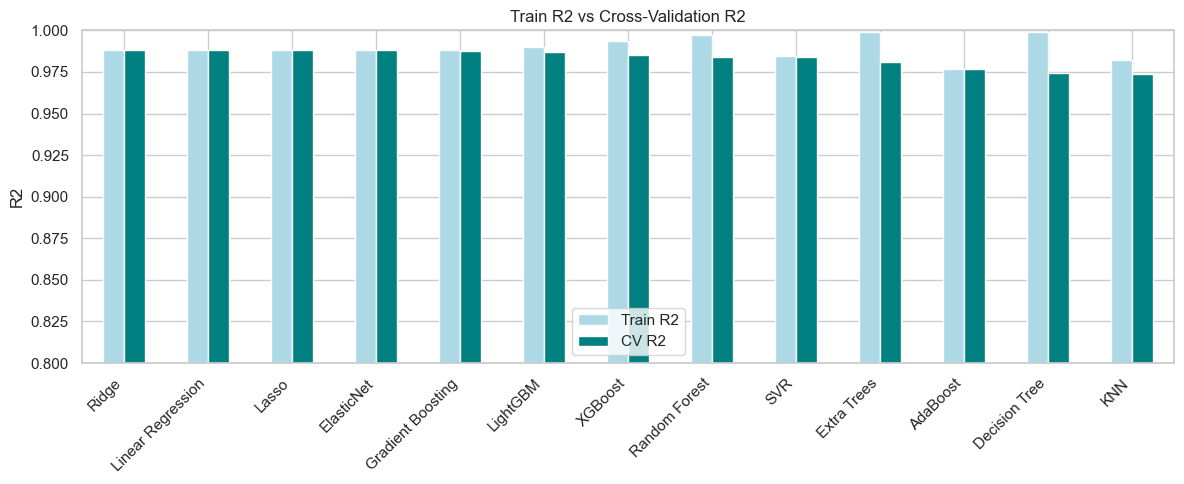

In [21]:
comparison[['Train R2', 'CV R2']].plot(kind='bar', figsize=(12, 5), color=['lightblue', 'teal'])
plt.ylim(0.8, 1.0)
plt.title('Train R2 vs Cross-Validation R2')
plt.ylabel('R2')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Comparison results (5-fold CV on the training data)**
- **Linear models win:** Ridge, Linear Regression and Lasso all reach **CV R² 0.9883** (RMSE ≈ 2.1 points). The EDA showed straight-line relations, and a linear model fits them exactly.
- Train R² = CV R² for the linear models → **no overfitting**.
- **Boosting** (Gradient Boosting 0.987, LightGBM 0.987, XGBoost 0.985) is very close but a bit worse: trees approximate a straight line with "steps".
- **Overfitting:** Decision Tree and Extra Trees reach 0.999 on training but 0.974 / 0.981 in CV.
- **KNN** (0.974) is the weakest – it averages neighbours instead of following the line.
- Lesson: **a more complex model is not always better** – when the relation is linear, the simplest model is the best and the easiest to explain.

# GridSearchCV (top 3 models)

A parameter grid is prepared for every model; the **top 3 models** from the comparison table are tuned with 5-fold cross-validation on the training data.

In [22]:
param_grids = {
    'Linear Regression': {'model__fit_intercept': [True, False]},
    'Ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100]},
    'Lasso': {'model__alpha': [0.0001, 0.001, 0.01, 0.1]},
    'ElasticNet': {'model__alpha': [0.0001, 0.001, 0.01], 'model__l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'model__n_neighbors': [5, 10, 20], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'model__n_estimators': [200, 400], 'model__max_features': [0.5, 1.0], 'model__min_samples_leaf': [1, 3]},
    'SVR': {'model__C': [10, 30, 100], 'model__epsilon': [0.1, 0.5]},
    'Gradient Boosting': {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]},
    'AdaBoost': {'model__n_estimators': [50, 100], 'model__learning_rate': [0.1, 1.0]},
    'Extra Trees': {'model__n_estimators': [200, 400], 'model__max_features': [0.5, 1.0], 'model__min_samples_leaf': [1, 3]},
    'XGBoost': {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]},
    'LightGBM': {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__num_leaves': [7, 15]},
}

In [23]:
top_models = comparison.index[:3]
grids = {}

for name in top_models:
    pipe = Pipeline([('preprocessor', preprocessor), ('model', models[name])])
    grid = GridSearchCV(pipe, param_grids[name], cv=kfold, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    grids[name] = grid

    print('=' * 60)
    print(name)
    print('Parameter grid :', param_grids[name])
    print('best_params_   :', grid.best_params_)
    print('best_score_    :', round(grid.best_score_, 5), '(CV R2)')

Ridge
Parameter grid : {'model__alpha': [0.01, 0.1, 1, 10, 100]}
best_params_   : {'model__alpha': 1}
best_score_    : 0.98826 (CV R2)
Linear Regression
Parameter grid : {'model__fit_intercept': [True, False]}
best_params_   : {'model__fit_intercept': True}
best_score_    : 0.98826 (CV R2)


Lasso
Parameter grid : {'model__alpha': [0.0001, 0.001, 0.01, 0.1]}
best_params_   : {'model__alpha': 0.0001}
best_score_    : 0.98826 (CV R2)


## Before vs after tuning (cross-validation R2)

In [24]:
tuning = pd.DataFrame({
    'CV R2 before tuning': comparison.loc[top_models, 'CV R2'],
    'CV R2 after tuning': [grids[name].best_score_ for name in top_models],
})
tuning['Improvement'] = tuning['CV R2 after tuning'] - tuning['CV R2 before tuning']
tuning['Best params'] = [grids[name].best_params_ for name in top_models]
tuning = tuning.sort_values('CV R2 after tuning', ascending=False)
tuning.style.format({'CV R2 before tuning': '{:.5f}', 'CV R2 after tuning': '{:.5f}', 'Improvement': '{:.5f}'})

,CV R2 before tuning,CV R2 after tuning,Improvement,Best params
Ridge,0.98826,0.98826,0.00000,{'model__alpha': 1}
Linear Regression,0.98826,0.98826,0.00000,{'model__fit_intercept': True}
Lasso,0.98826,0.98826,0.00000,{'model__alpha': 0.0001}


In [25]:
best_name = tuning.index[0]   # chosen by the cross-validation score, not by the test set
best_model = grids[best_name].best_estimator_
print('Best model :', best_name)
print('Best params:', grids[best_name].best_params_)

Best model : Ridge
Best params: {'model__alpha': 1}


# Final Evaluation on the Test Set

In [26]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

base_model = Pipeline([('preprocessor', preprocessor), ('model', models[best_name])]).fit(X_train, y_train)   # before tuning
y_pred = best_model.predict(X_test)

final = pd.DataFrame({
    'Before tuning': regression_metrics(y_test, base_model.predict(X_test)),
    'After tuning': regression_metrics(y_test, y_pred),
}).T
final.round(4)

,MAE,MSE,RMSE,R2
Before tuning,1.6542,4.314,2.077,0.9886
After tuning,1.6542,4.314,2.077,0.9886


In [27]:
errors = np.abs(y_test - y_pred)
print('Predictions within ±2 points :', round((errors <= 2).mean() * 100, 1), '%')
print('Predictions within ±4 points :', round((errors <= 4).mean() * 100, 1), '%')
print('Largest error                :', round(errors.max(), 1), 'points')

Predictions within ±2 points : 66.7 %
Predictions within ±4 points : 94.3 %
Largest error                : 8.7 points


## Actual vs Predicted

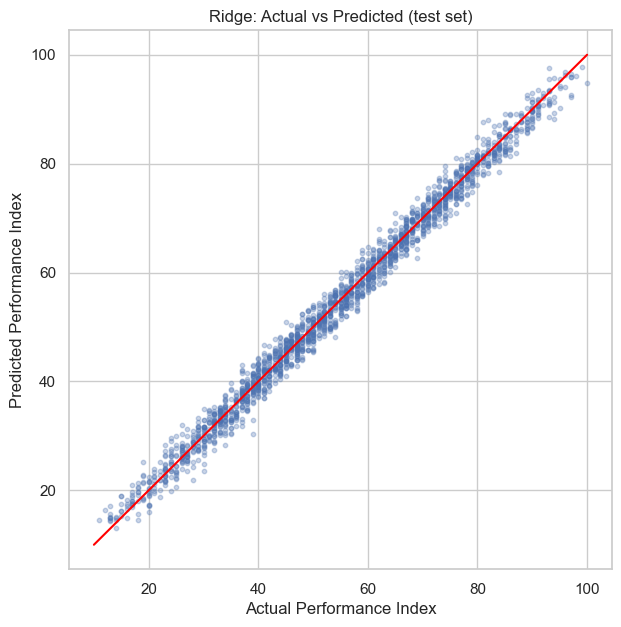

In [28]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
plt.plot([10, 100], [10, 100], color='red')
plt.xlabel('Actual Performance Index')
plt.ylabel('Predicted Performance Index')
plt.title(best_name + ': Actual vs Predicted (test set)')
plt.show()

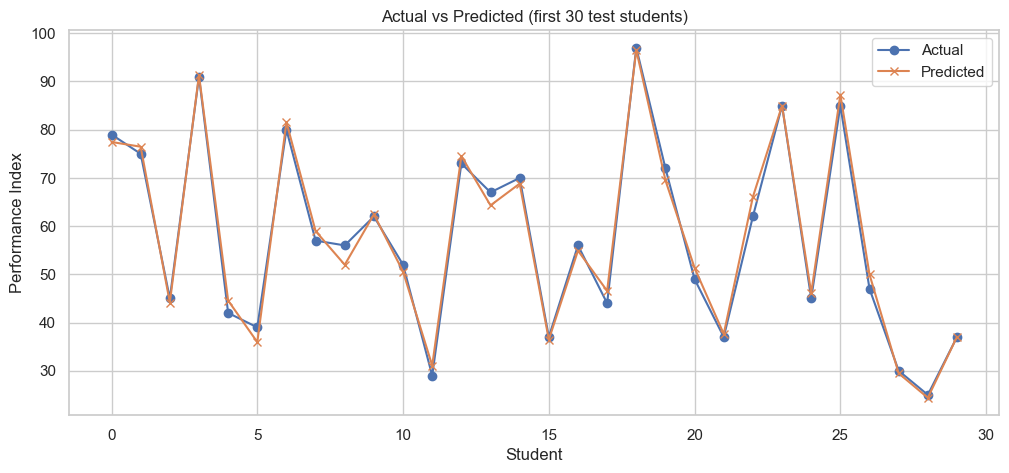

In [29]:
plt.figure(figsize=(12, 5))
plt.plot(range(30), y_test.values[:30], marker='o', label='Actual')
plt.plot(range(30), y_pred[:30], marker='x', label='Predicted')
plt.xlabel('Student')
plt.ylabel('Performance Index')
plt.title('Actual vs Predicted (first 30 test students)')
plt.legend()
plt.show()

## Residuals

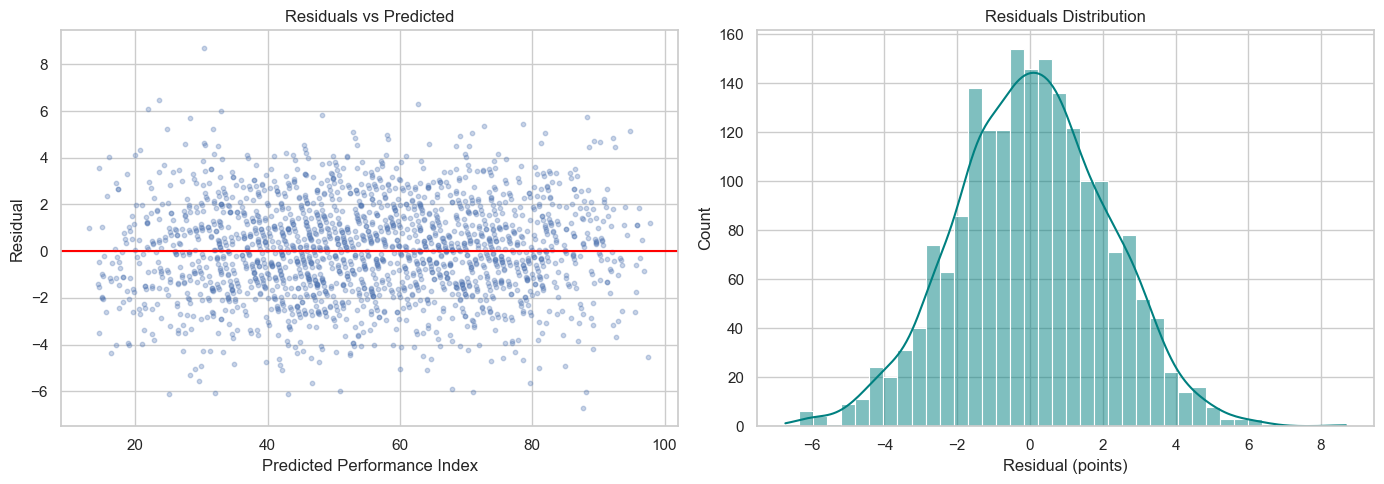

In [30]:
residuals = y_test - y_pred

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_pred, residuals, alpha=0.3, s=10)
ax[0].axhline(0, color='red')
ax[0].set_xlabel('Predicted Performance Index')
ax[0].set_ylabel('Residual')
ax[0].set_title('Residuals vs Predicted')
sns.histplot(residuals, bins=40, color='teal', kde=True, ax=ax[1])
ax[1].set_xlabel('Residual (points)')
ax[1].set_title('Residuals Distribution')
plt.tight_layout()
plt.show()

## Which features matter?

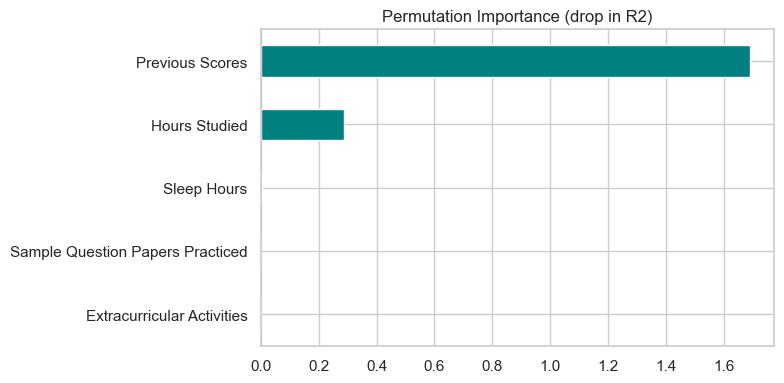

In [31]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, scoring='r2', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind='barh', color='teal')
plt.title('Permutation Importance (drop in R2)')
plt.tight_layout()
plt.show()

In [32]:
# a simple linear model is easy to explain: each coefficient = points gained per 1 unit (on the original scale)
lr = Pipeline([('preprocessor', preprocessor), ('model', LinearRegression())]).fit(X_train, y_train)
scales = list(lr.named_steps['preprocessor'].named_transformers_['num'].named_steps['scaler'].scale_) + [1]
coef = pd.Series(lr.named_steps['model'].coef_ / np.array(scales), index=num_cols + ['Extracurricular = Yes'])
coef.round(3)

Hours Studied                       2.861
Previous Scores                     1.017
Sleep Hours                         0.480
Sample Question Papers Practiced    0.191
Extracurricular = Yes               0.479
dtype: float64

**Interpretation of errors & discussion of model performance**
- **GridSearchCV:** the top 3 are all linear (Ridge, Linear Regression, Lasso). Tuning gave **no improvement** (all stay at 0.98826): the best Ridge alpha is 1 (the default)
  and the best Lasso alpha is the smallest one – i.e. **regularization is not needed** because there are only 5 clean, independent features and ~8,000 rows.
  Ridge is chosen (first in the table; it is identical to Linear Regression here).
- **Test set:** **R² = 0.989**, MAE = 1.65 points, RMSE = 2.08 points (on a 10 – 100 scale). 67 % of predictions are within ±2 points and 94 % within ±4 points; the largest error is 8.7 points.
  The test result equals the CV result → the model generalizes perfectly.
- **Actual vs Predicted:** all points lie on the red line, for weak and strong students alike.
- **Residuals:** centered at 0, normal (bell-shaped), same spread everywhere → the linear model assumptions hold. The remaining ±2 points are random noise
  (plus the missing values that were filled with the median).
- **Coefficients (easy to explain):** every extra **hour of study = +2.86 points**, every extra **previous-score point = +1.02**, every extra **hour of sleep = +0.48**,
  each **practice paper = +0.19**, and **extracurricular activities = +0.48**.
- **Most important feature:** Previous Scores, then Hours Studied; the other three have small effects.

# Save the model (for the Gradio app)

In [33]:
import joblib

joblib.dump(best_model, 'models/student_model.pkl')

loaded_model = joblib.load('models/student_model.pkl')
new_student = pd.DataFrame([{
    'Hours Studied': 7, 'Previous Scores': 85, 'Sleep Hours': 8,
    'Sample Question Papers Practiced': 5, 'Extracurricular Activities': 'Yes',
}])
print('Predicted Performance Index:', round(loaded_model.predict(new_student)[0], 1))

Predicted Performance Index: 77.8


# Gradio App (deployment)
The saved pipeline (`loaded_model`) is put into a small web app. The user enters the study habits and previous scores,
and the app shows the predicted Performance Index with a simple level (high / average / low).

- Run the cell below to open the app **inside the notebook** (or at the local link it prints).
- The same code is in [`app.py`](app.py), which is the file used for the live deployment on Hugging Face Spaces.

In [34]:
import gradio as gr

def predict_performance(hours_studied, previous_scores, extracurricular, sleep_hours, sample_papers):
    student = pd.DataFrame([{
        'Hours Studied': hours_studied, 'Previous Scores': previous_scores, 'Sleep Hours': sleep_hours,
        'Sample Question Papers Practiced': sample_papers, 'Extracurricular Activities': extracurricular,
    }])
    score = float(loaded_model.predict(student)[0])
    score = min(max(score, 10), 100)   # the index is between 10 and 100

    if score >= 70:
        level = 'High performance'
    elif score >= 40:
        level = 'Average performance'
    else:
        level = 'Low performance – needs support'
    return round(score, 1), level

demo = gr.Interface(
    fn=predict_performance,
    inputs=[
        gr.Slider(1, 9, value=5, step=1, label='Hours Studied (per day)'),
        gr.Slider(40, 99, value=70, step=1, label='Previous Scores'),
        gr.Radio(['Yes', 'No'], value='No', label='Extracurricular Activities'),
        gr.Slider(4, 9, value=7, step=1, label='Sleep Hours'),
        gr.Slider(0, 9, value=5, step=1, label='Sample Question Papers Practiced'),
    ],
    outputs=[
        gr.Number(label='Predicted Performance Index (10 – 100)'),
        gr.Textbox(label='Level'),
    ],
    examples=[[7, 85, 'Yes', 8, 5], [2, 45, 'No', 5, 1], [5, 70, 'No', 7, 3]],
    title='Student Performance Prediction',
    description='Predict a student\'s Performance Index from study habits and previous scores.',
)

demo.launch()

Running on local URL:  http://127.0.0.1:7862

To create a public link, set `share=True` in `launch()`.


In [35]:
# quick check: the app function gives the same answers as the model
for s in [[7, 85, 'Yes', 8, 5], [2, 45, 'No', 5, 1], [5, 70, 'No', 7, 3]]:
    print(f'hours = {s[0]}  previous = {s[1]}  ->', predict_performance(*s))

hours = 7  previous = 85  -> (77.8, 'High performance')
hours = 2  previous = 45  -> (20.1, 'Low performance – needs support')
hours = 5  previous = 70  -> (55.5, 'Average performance')


# Conclusions & Recommendations

**Conclusions**
1. After removing 132 duplicates and filling the missing values inside the pipeline, 9,868 students were used.
2. Performance depends mainly on **previous scores** and **study hours**; sleep, practice papers and extracurricular activities add small but real gains.
3. 13 regression models were compared; **linear models are the best** (CV R² 0.988), better than boosting and trees, and tuning brought no extra gain.
4. The final **Ridge** model reaches **R² = 0.989 on the test set** with an average error of 1.65 points, and it is saved for the **Gradio app**.

**Recommendations**
- Use the model to **find students at risk** early (low predicted index) and advise them – each extra study hour is worth almost 3 points.
- Encourage enough sleep and practice papers: small effects, but they add up.
- Collect the missing values properly (29 % of practice-paper values were missing) – this is the main remaining source of error.